# 📊 Dataset Description: CICIDS2017

## 📌 Overview
The dataset used in this project is the **CICIDS2017 dataset**, developed by the Canadian Institute for Cybersecurity. It is a widely used benchmark dataset for network intrusion detection research.

This dataset contains realistic network traffic data, including both normal (benign) activity and multiple types of cyber-attacks. It is designed to evaluate the performance of machine learning models for detecting and classifying network threats.

---

## 📂 Dataset Files Used

The dataset consists of multiple CSV files representing network traffic captured over different days:

- Monday-WorkingHours.pcap_ISCX.csv  
- Tuesday-WorkingHours.pcap_ISCX.csv  
- Wednesday-workingHours.pcap_ISCX.csv  
- Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv  
- Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv  
- Friday-WorkingHours-Morning.pcap_ISCX.csv  
- Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv  
- Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv  

All files are combined into a single dataset for training and evaluation.

---

## 🎯 Types of Network Traffic

The dataset includes two main categories:

### 1. Benign Traffic
- Normal network activity without any malicious behavior.

### 2. Malicious Traffic (Attacks)
The dataset includes multiple attack types such as:

- DDoS (Distributed Denial of Service)  
- DoS (Denial of Service)  
- Brute Force (FTP/SSH)  
- Botnet Attacks  
- Port Scanning  
- Web Attacks (SQL Injection, XSS)  
- Infiltration Attacks  

---

## 📊 Features

- The dataset contains **80+ network traffic features**
- Examples include:
  - Flow Duration  
  - Total Forward Packets  
  - Total Backward Packets  
  - Flow Bytes/s  
  - Packet Length Statistics  
  - Flow Inter-arrival Time  

These features are extracted from raw network traffic to represent behavioral patterns.

---

## 🏷️ Target Variable

- The dataset includes a **label column**:
  
  `Label`

- This column indicates whether the traffic is:
  - BENIGN  
  - or a specific attack type

---

## ⚙️ Data Preprocessing

Before training the model, the following preprocessing steps are applied:

- Merging all CSV files into one dataset  
- Removing missing (NaN) values  
- Handling infinite values  
- Encoding categorical labels  
- Feature scaling (normalization/standardization)  
- Perform EDA
- Handle Impbalance class

---

## 🚀 Purpose of Using This Dataset

This dataset is used to:

- Train machine learning models for intrusion detection  
- Classify different types of cyber-attacks  
- Evaluate model performance on realistic network data  
- Fine Tunned Models and Again Evaluate Model Performance
- Develop an AI-based threat detection and mitigation framework  

---

## 📎 Source

Canadian Institute for Cybersecurity  
https://www.unb.ca/cic/datasets/ids-2017.html

### Define dataset folder path and Check if dataset folder exists

In [2]:
import os
import pandas as pd

DATASET_PATH = "data"

if not os.path.exists(DATASET_PATH):
    raise FileNotFoundError(
        f"Dataset folder not found: {DATASET_PATH}\n"
        "Please make sure your CSV files are placed inside data/"
    )

#### Find all CSV files

In [3]:
csv_files = [file for file in os.listdir(DATASET_PATH) if file.endswith(".csv")]

print("Number of CSV files found:", len(csv_files))
print("\nCSV files:")
for file in csv_files:
    print("-", file)

Number of CSV files found: 8

CSV files:
- Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
- Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv
- Friday-WorkingHours-Morning.pcap_ISCX.csv
- Monday-WorkingHours.pcap_ISCX.csv
- Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv
- Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv
- Tuesday-WorkingHours.pcap_ISCX.csv
- Wednesday-workingHours.pcap_ISCX.csv


#### Read and merge all CSV files

In [4]:
dataframes = []

for file in csv_files:
    file_path = os.path.join(DATASET_PATH, file)
    print(f"\nLoading: {file}")

    df = pd.read_csv(file_path)
    print(f"Shape of {file}: {df.shape}")

    dataframes.append(df)


Loading: Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
Shape of Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv: (225745, 79)

Loading: Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv
Shape of Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv: (286467, 79)

Loading: Friday-WorkingHours-Morning.pcap_ISCX.csv
Shape of Friday-WorkingHours-Morning.pcap_ISCX.csv: (191033, 79)

Loading: Monday-WorkingHours.pcap_ISCX.csv
Shape of Monday-WorkingHours.pcap_ISCX.csv: (529918, 79)

Loading: Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv
Shape of Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv: (288602, 79)

Loading: Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv
Shape of Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv: (170366, 79)

Loading: Tuesday-WorkingHours.pcap_ISCX.csv
Shape of Tuesday-WorkingHours.pcap_ISCX.csv: (445909, 79)

Loading: Wednesday-workingHours.pcap_ISCX.csv
Shape of Wednesday-workingHours.pcap_ISCX.csv: (692703, 79)


#### Combine all files into one dataframe

In [5]:
combined_df = pd.concat(dataframes, ignore_index=True)

print("\n==================================================")
print("Final Combined Dataset Shape:", combined_df.shape)
print("==================================================")


Final Combined Dataset Shape: (2830743, 79)


#### Display first few rows

In [6]:
print("\nFirst 5 rows:")
print(combined_df.head())


First 5 rows:
    Destination Port   Flow Duration   Total Fwd Packets  \
0              54865               3                   2   
1              55054             109                   1   
2              55055              52                   1   
3              46236              34                   1   
4              54863               3                   2   

    Total Backward Packets  Total Length of Fwd Packets  \
0                        0                           12   
1                        1                            6   
2                        1                            6   
3                        1                            6   
4                        0                           12   

    Total Length of Bwd Packets   Fwd Packet Length Max  \
0                             0                       6   
1                             6                       6   
2                             6                       6   
3                             6  

#### Display column names

In [7]:
print("\nTotal Columns:", len(combined_df.columns))
print("\nColumn Names:")
print(combined_df.columns.tolist())


Total Columns: 79

Column Names:
[' Destination Port', ' Flow Duration', ' Total Fwd Packets', ' Total Backward Packets', 'Total Length of Fwd Packets', ' Total Length of Bwd Packets', ' Fwd Packet Length Max', ' Fwd Packet Length Min', ' Fwd Packet Length Mean', ' Fwd Packet Length Std', 'Bwd Packet Length Max', ' Bwd Packet Length Min', ' Bwd Packet Length Mean', ' Bwd Packet Length Std', 'Flow Bytes/s', ' Flow Packets/s', ' Flow IAT Mean', ' Flow IAT Std', ' Flow IAT Max', ' Flow IAT Min', 'Fwd IAT Total', ' Fwd IAT Mean', ' Fwd IAT Std', ' Fwd IAT Max', ' Fwd IAT Min', 'Bwd IAT Total', ' Bwd IAT Mean', ' Bwd IAT Std', ' Bwd IAT Max', ' Bwd IAT Min', 'Fwd PSH Flags', ' Bwd PSH Flags', ' Fwd URG Flags', ' Bwd URG Flags', ' Fwd Header Length', ' Bwd Header Length', 'Fwd Packets/s', ' Bwd Packets/s', ' Min Packet Length', ' Max Packet Length', ' Packet Length Mean', ' Packet Length Std', ' Packet Length Variance', 'FIN Flag Count', ' SYN Flag Count', ' RST Flag Count', ' PSH Flag Coun

#### Check target column

In [ ]:
if " Label" in combined_df.columns:
    print("\nTarget column found as: ' Label'")
    print("\nClass distribution:")
    print(combined_df[" Label"].value_counts())
elif "Label" in combined_df.columns:
    print("\nTarget column found as: 'Label'")
    print("\nClass distribution:")
    print(combined_df["Label"].value_counts())
else:
    print("\nWARNING: Label column not found.")
    print("Check column names carefully.")


Target column found as: ' Label'

Class distribution:
 Label
BENIGN                        2273097
DoS Hulk                       231073
PortScan                       158930
DDoS                           128027
DoS GoldenEye                   10293
FTP-Patator                      7938
SSH-Patator                      5897
DoS slowloris                    5796
DoS Slowhttptest                 5499
Bot                              1966
Web Attack � Brute Force         1507
Web Attack � XSS                  652
Infiltration                       36
Web Attack � Sql Injection         21
Heartbleed                         11
Name: count, dtype: int64


## Dataset Cleaning

#### Remove extra spaces from column names

In [9]:
import numpy as np

combined_df.columns = combined_df.columns.str.strip()

print("Column names cleaned successfully.")
print("Target column after cleaning:", "Label" if "Label" in combined_df.columns else "Label not found")

Column names cleaned successfully.
Target column after cleaning: Label


#### Fix broken label names

In [10]:
combined_df["Label"] = combined_df["Label"].astype(str).str.strip()

label_corrections = {
    "Web Attack � Brute Force": "Web Attack Brute Force",
    "Web Attack � XSS": "Web Attack XSS",
    "Web Attack � Sql Injection": "Web Attack Sql Injection"
}

combined_df["Label"] = combined_df["Label"].replace(label_corrections)

print("\nLabels corrected successfully.")


Labels corrected successfully.


#### Replace infinite values with NaN

In [11]:
combined_df.replace([np.inf, -np.inf], np.nan, inplace=True)

print("\nInfinite values replaced with NaN.")


Infinite values replaced with NaN.


#### Check missing values before cleaning

In [12]:
missing_before = combined_df.isnull().sum().sum()
print("\nTotal missing values before cleaning:", missing_before)



Total missing values before cleaning: 5734


#### Remove missing values

In [13]:
combined_df.dropna(inplace=True)

missing_after = combined_df.isnull().sum().sum()
print("Total missing values after cleaning:", missing_after)

Total missing values after cleaning: 0


#### Remove duplicate rows

In [14]:
duplicates_before = combined_df.duplicated().sum()
print("\nDuplicate rows before removal:", duplicates_before)

combined_df.drop_duplicates(inplace=True)

duplicates_after = combined_df.duplicated().sum()
print("Duplicate rows after removal:", duplicates_after)


Duplicate rows before removal: 307078
Duplicate rows after removal: 0


#### Final cleaned dataset shape

In [15]:
print("\n==================================================")
print("Cleaned Dataset Shape:", combined_df.shape)
print("==================================================")


Cleaned Dataset Shape: (2520798, 79)


#### Clean class distribution

In [16]:
print("\nCleaned Class Distribution:")
print(combined_df["Label"].value_counts())


Cleaned Class Distribution:
Label
BENIGN                      2095057
DoS Hulk                     172846
DDoS                         128014
PortScan                      90694
DoS GoldenEye                 10286
FTP-Patator                    5931
DoS slowloris                  5385
DoS Slowhttptest               5228
SSH-Patator                    3219
Bot                            1948
Web Attack Brute Force         1470
Web Attack XSS                  652
Infiltration                     36
Web Attack Sql Injection         21
Heartbleed                       11
Name: count, dtype: int64


### Data Analysis + Visualization

In [17]:
import matplotlib.pyplot as plt
import seaborn as sns

#### Class distribution

In [18]:
class_counts = combined_df["Label"].value_counts()

print("\nClass Distribution:")
print(class_counts)


Class Distribution:
Label
BENIGN                      2095057
DoS Hulk                     172846
DDoS                         128014
PortScan                      90694
DoS GoldenEye                 10286
FTP-Patator                    5931
DoS slowloris                  5385
DoS Slowhttptest               5228
SSH-Patator                    3219
Bot                            1948
Web Attack Brute Force         1470
Web Attack XSS                  652
Infiltration                     36
Web Attack Sql Injection         21
Heartbleed                       11
Name: count, dtype: int64


### Plot class distribution

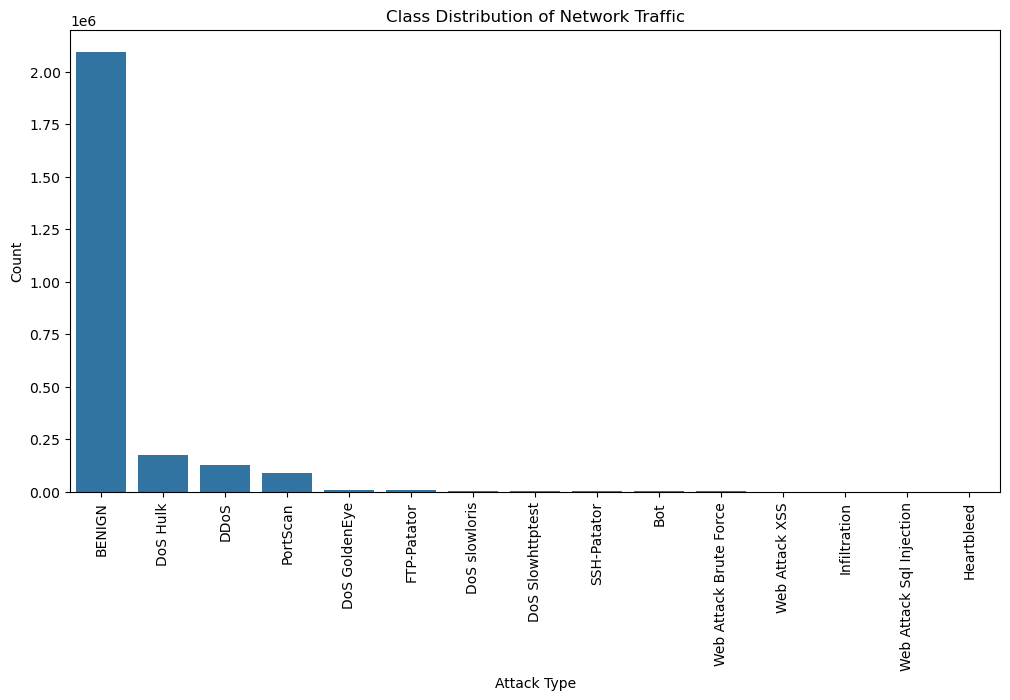

In [19]:
plt.figure(figsize=(12, 6))
sns.barplot(x=class_counts.index, y=class_counts.values)

plt.title("Class Distribution of Network Traffic")
plt.xlabel("Attack Type")
plt.ylabel("Count")
plt.xticks(rotation=90)

plt.show()

### Percentage distribution

In [20]:
class_percent = (class_counts / len(combined_df)) * 100

print("\nClass Percentage Distribution:")
print(class_percent)


Class Percentage Distribution:
Label
BENIGN                      83.110864
DoS Hulk                     6.856797
DDoS                         5.078313
PortScan                     3.597829
DoS GoldenEye                0.408045
FTP-Patator                  0.235283
DoS slowloris                0.213623
DoS Slowhttptest             0.207395
SSH-Patator                  0.127698
Bot                          0.077277
Web Attack Brute Force       0.058315
Web Attack XSS               0.025865
Infiltration                 0.001428
Web Attack Sql Injection     0.000833
Heartbleed                   0.000436
Name: count, dtype: float64


#### Identify rare classes

In [21]:
rare_classes = class_counts[class_counts < 1000]

print("\nRare Classes (Less than 1000 samples):")
print(rare_classes)


Rare Classes (Less than 1000 samples):
Label
Web Attack XSS              652
Infiltration                 36
Web Attack Sql Injection     21
Heartbleed                   11
Name: count, dtype: int64


### Exploratory Data Analysis

#### Data Types

In [22]:
print("\nData Types:")
print(combined_df.dtypes.value_counts())


Data Types:
int64      54
float64    24
str         1
Name: count, dtype: int64


#### Statistical Summary

In [23]:
print("\nStatistical Summary:")
print(combined_df.describe())


Statistical Summary:
       Destination Port  Flow Duration  Total Fwd Packets  \
count      2.520798e+06   2.520798e+06       2.520798e+06   
mean       8.690590e+03   1.659161e+07       1.028174e+01   
std        1.901280e+04   3.523276e+07       7.944201e+02   
min        0.000000e+00  -1.300000e+01       1.000000e+00   
25%        5.300000e+01   2.080000e+02       2.000000e+00   
50%        8.000000e+01   5.062200e+04       2.000000e+00   
75%        4.430000e+02   5.333340e+06       6.000000e+00   
max        6.553500e+04   1.200000e+08       2.197590e+05   

       Total Backward Packets  Total Length of Fwd Packets  \
count            2.520798e+06                 2.520798e+06   
mean             1.157280e+01                 6.119477e+02   
std              1.056922e+03                 1.058827e+04   
min              0.000000e+00                 0.000000e+00   
25%              1.000000e+00                 1.200000e+01   
50%              2.000000e+00                 6.600000e+

#### Correlation Analysis

Original sample shape: (50000, 79)
Numeric sample shape: (50000, 78)


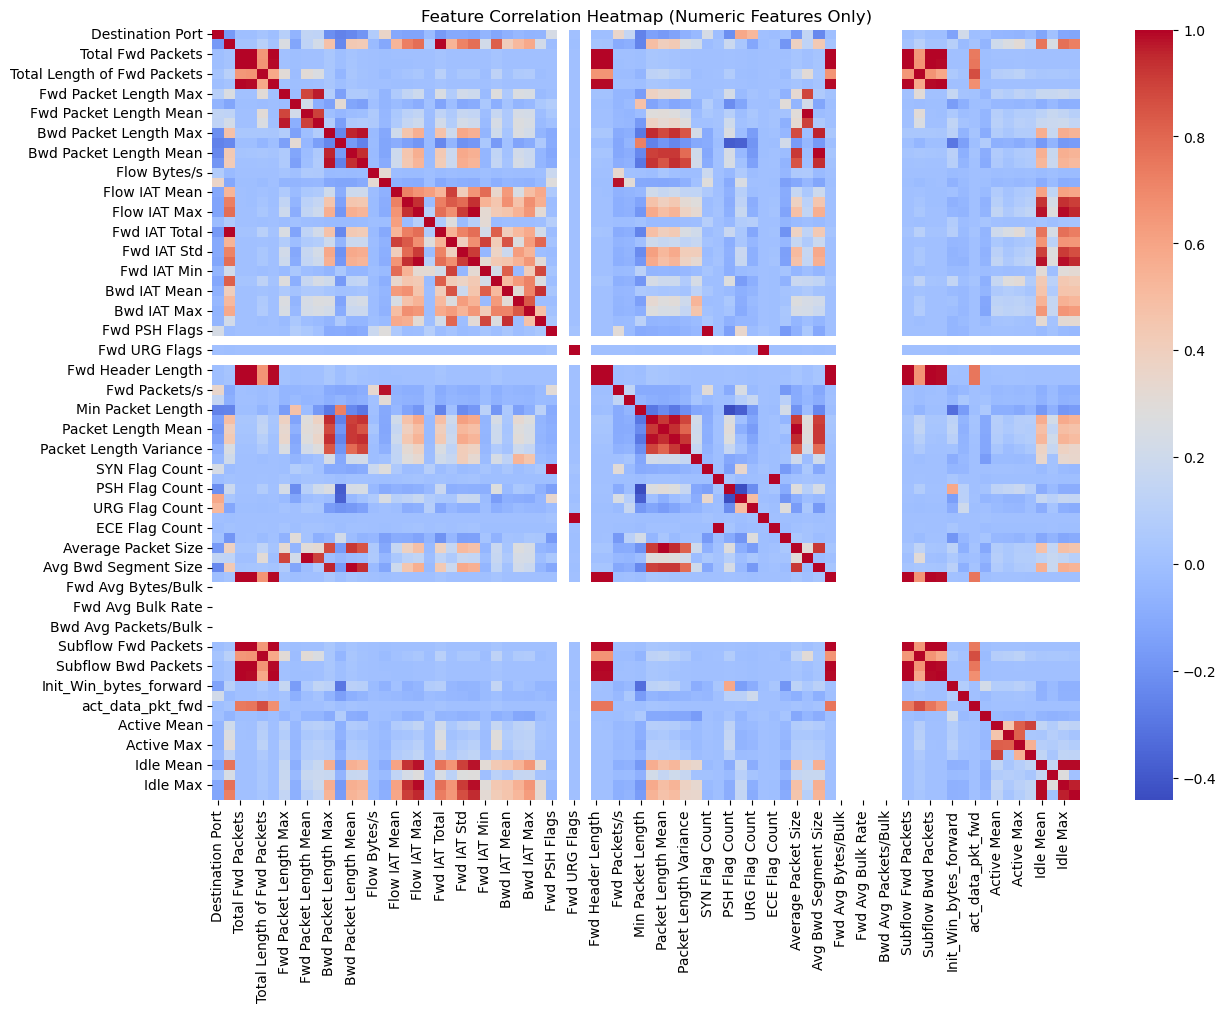

In [28]:
sample_df = combined_df.sample(n=50000, random_state=42)

numeric_sample_df = sample_df.select_dtypes(include=["int64", "float64"])

print("Original sample shape:", sample_df.shape)
print("Numeric sample shape:", numeric_sample_df.shape)

corr_matrix = numeric_sample_df.corr()

plt.figure(figsize=(14, 10))
sns.heatmap(corr_matrix, cmap="coolwarm")

plt.title("Feature Correlation Heatmap (Numeric Features Only)")
plt.show()

#### Constant Features

In [29]:
constant_columns = [col for col in combined_df.columns if combined_df[col].nunique() == 1]

print("\nConstant Columns (useless features):")
print(constant_columns)


Constant Columns (useless features):
['Bwd PSH Flags', 'Bwd URG Flags', 'Fwd Avg Bytes/Bulk', 'Fwd Avg Packets/Bulk', 'Fwd Avg Bulk Rate', 'Bwd Avg Bytes/Bulk', 'Bwd Avg Packets/Bulk', 'Bwd Avg Bulk Rate']


#### Feature Distribution

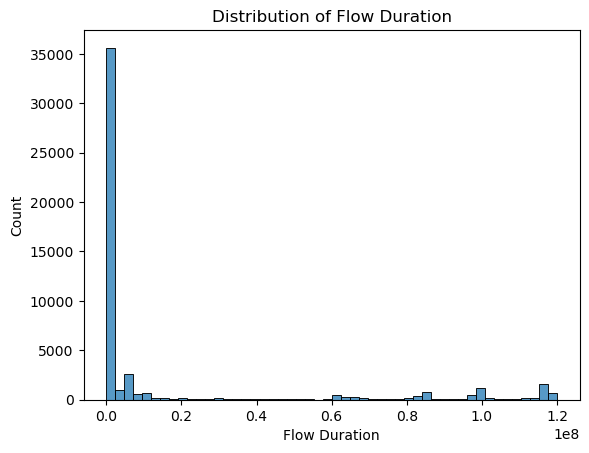

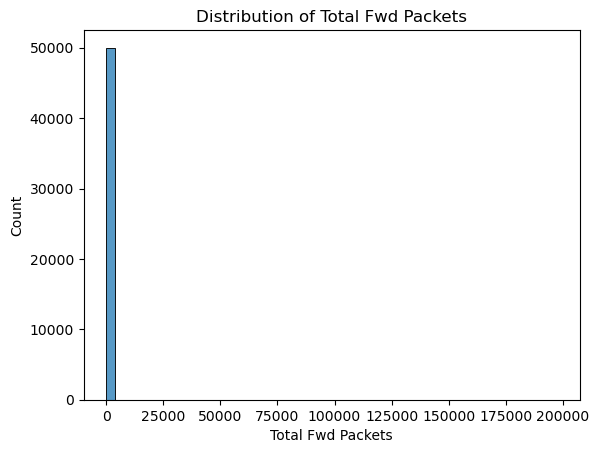

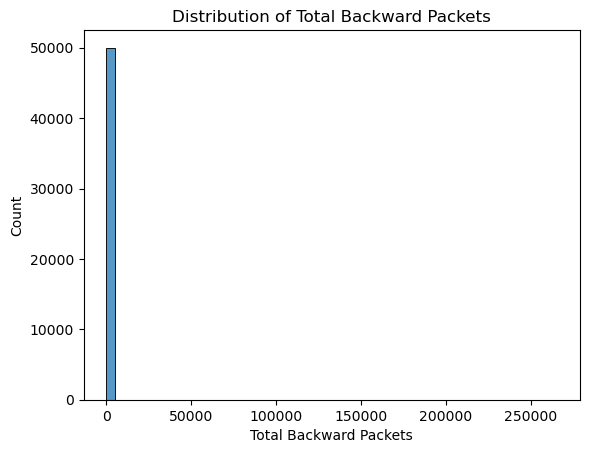

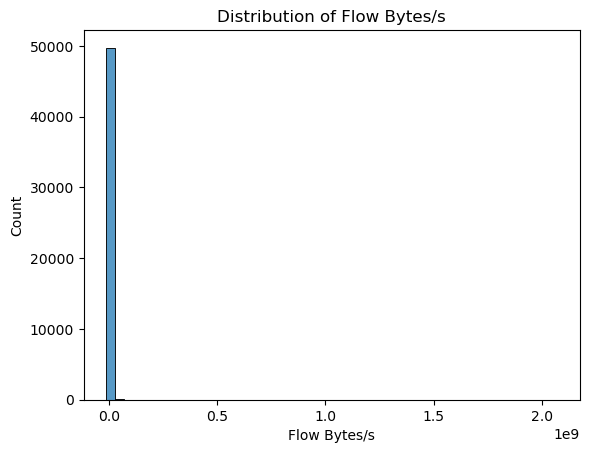

In [30]:
important_features = [
    "Flow Duration",
    "Total Fwd Packets",
    "Total Backward Packets",
    "Flow Bytes/s"
]

sample_df = combined_df.sample(n=50000, random_state=42)

for feature in important_features:
    plt.figure()
    sns.histplot(sample_df[feature], bins=50)
    plt.title(f"Distribution of {feature}")
    plt.show()

#### Skewness Check

In [31]:
skewness = combined_df.skew(numeric_only=True)

print("\nTop 10 Highly Skewed Features:")
print(skewness.sort_values(ascending=False).head(10))


Top 10 Highly Skewed Features:
Total Length of Fwd Packets    760.581442
Subflow Fwd Bytes              758.720646
act_data_pkt_fwd               268.563578
Subflow Bwd Packets            230.896626
Total Backward Packets         230.896626
Total Fwd Packets              230.614791
Subflow Fwd Packets            230.614791
Subflow Bwd Bytes              230.570871
Total Length of Bwd Packets    230.566712
Fwd URG Flags                  177.502148
dtype: float64


### Feature Cleaning

#### Remove Constant Features

In [32]:
constant_columns = [col for col in combined_df.columns if combined_df[col].nunique() == 1]

print("Removing constant columns:")
print(constant_columns)

combined_df.drop(columns=constant_columns, inplace=True)

print("\nNew shape after removing constants:", combined_df.shape)

Removing constant columns:
['Bwd PSH Flags', 'Bwd URG Flags', 'Fwd Avg Bytes/Bulk', 'Fwd Avg Packets/Bulk', 'Fwd Avg Bulk Rate', 'Bwd Avg Bytes/Bulk', 'Bwd Avg Packets/Bulk', 'Bwd Avg Bulk Rate']

New shape after removing constants: (2520798, 71)


#### Remove Highly Correlated Features

In [ ]:
sample_df = combined_df.sample(n=50000, random_state=42)

numeric_sample_df = sample_df.select_dtypes(include=["int64", "float64"])

corr_matrix = numeric_sample_df.corr().abs()

upper_triangle = corr_matrix.where(
    np.triu(np.ones(corr_matrix.shape), k=1).astype(bool)
)

to_drop = [
    column for column in upper_triangle.columns
    if any(upper_triangle[column] > 0.9)
]

print("\nHighly correlated features to remove:")
print(to_drop)

combined_df.drop(columns=to_drop, inplace=True)

print("\nNew shape after removing correlated features:", combined_df.shape)


Highly correlated features to remove:
['Total Backward Packets', 'Total Length of Bwd Packets', 'Fwd Packet Length Std', 'Bwd Packet Length Mean', 'Bwd Packet Length Std', 'Flow IAT Max', 'Fwd IAT Total', 'Fwd IAT Mean', 'Fwd IAT Std', 'Fwd IAT Max', 'Bwd IAT Min', 'Fwd Header Length', 'Bwd Header Length', 'Fwd Packets/s', 'Max Packet Length', 'Packet Length Mean', 'Packet Length Std', 'Packet Length Variance', 'SYN Flag Count', 'CWE Flag Count', 'ECE Flag Count', 'Average Packet Size', 'Avg Fwd Segment Size', 'Avg Bwd Segment Size', 'Fwd Header Length.1', 'Subflow Fwd Packets', 'Subflow Fwd Bytes', 'Subflow Bwd Packets', 'Subflow Bwd Bytes', 'Idle Mean', 'Idle Max', 'Idle Min']

New shape after removing correlated features: (2520798, 39)


**NOTE:** Highly correlated features were removed using a threshold of 0.9 to reduce redundancy and improve computational efficiency. This step reduced the feature space from 79 to 39 while preserving essential information.

### Model-Ready Data Preparation

In [35]:
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split


X = combined_df.drop("Label", axis=1)
y = combined_df["Label"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)


Features shape: (2520798, 38)
Target shape: (2520798,)


#### Encode Labels

In [36]:
label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y)

print("\nLabel Encoding Done")
print("Classes:", label_encoder.classes_)


Label Encoding Done
Classes: ['BENIGN' 'Bot' 'DDoS' 'DoS GoldenEye' 'DoS Hulk' 'DoS Slowhttptest'
 'DoS slowloris' 'FTP-Patator' 'Heartbleed' 'Infiltration' 'PortScan'
 'SSH-Patator' 'Web Attack Brute Force' 'Web Attack Sql Injection'
 'Web Attack XSS']


#### Train-Test Split

In [37]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y_encoded,
    test_size=0.2,
    random_state=42,
    stratify=y_encoded
)

print("\nTrain-Test Split Done")
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)


Train-Test Split Done
X_train: (2016638, 38)
X_test: (504160, 38)


#### Feature Scaling

In [38]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("\nScaling Done")
print("Scaled Training Shape:", X_train_scaled.shape)


Scaling Done
Scaled Training Shape: (2016638, 38)


#### Train First Model Random Forest

#### Train Random Forest Sampled Data

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

sample_size = 200000

X_train_sample = X_train_scaled[:sample_size]
y_train_sample = y_train[:sample_size]

print("Training on sample size:", X_train_sample.shape)

Training on sample size: (200000, 38)


#### Train model

In [40]:
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train_sample, y_train_sample)

print("\nModel Training Complete")




Model Training Complete


#### Predict on test set small portion

In [41]:
X_test_sample = X_test_scaled[:50000]
y_test_sample = y_test[:50000]

y_pred = rf_model.predict(X_test_sample)


#### Evaluate

In [42]:
accuracy = accuracy_score(y_test_sample, y_pred)

print("\nAccuracy:", accuracy)

print("\nClassification Report:")
print(classification_report(y_test_sample, y_pred))


Accuracy: 0.99854

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     41598
           1       0.89      0.73      0.80        33
           2       1.00      1.00      1.00      2455
           3       0.99      0.98      0.99       202
           4       1.00      1.00      1.00      3430
           5       1.00      0.98      0.99       106
           6       0.99      0.98      0.99       118
           7       1.00      0.99      1.00       130
          10       0.99      1.00      0.99      1832
          11       1.00      0.97      0.98        58
          12       0.84      0.87      0.85        30
          13       0.00      0.00      0.00         1
          14       0.67      0.29      0.40         7

    accuracy                           1.00     50000
   macro avg       0.87      0.83      0.84     50000
weighted avg       1.00      1.00      1.00     50000



c:\Users\msn\miniconda3\envs\ml_env\Lib\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\msn\miniconda3\envs\ml_env\Lib\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\msn\miniconda3\envs\ml_env\Lib\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape

#### Fix Imbalance

##### Handle Class Imbalance

In [43]:
df_balanced = X.copy()
df_balanced["Label"] = y

benign_df = df_balanced[df_balanced["Label"] == "BENIGN"]
attack_df = df_balanced[df_balanced["Label"] != "BENIGN"]

print("Original BENIGN:", len(benign_df))
print("Original ATTACK:", len(attack_df))

Original BENIGN: 2095057
Original ATTACK: 425741


#### Undersample BENIGN

In [44]:
benign_sample = benign_df.sample(n=len(attack_df), random_state=42)

# Combine again
balanced_df = pd.concat([benign_sample, attack_df])

print("\nBalanced dataset shape:", balanced_df.shape)


Balanced dataset shape: (851482, 39)


#### Shuffle dataset

In [45]:
balanced_df = balanced_df.sample(frac=1, random_state=42)

# Split again
X_bal = balanced_df.drop("Label", axis=1)
y_bal = balanced_df["Label"]

# Encode labels again
from sklearn.preprocessing import LabelEncoder

label_encoder_bal = LabelEncoder()
y_bal_encoded = label_encoder_bal.fit_transform(y_bal)

print("\nBalanced Classes:")
print(pd.Series(y_bal).value_counts())


Balanced Classes:
Label
BENIGN                      425741
DoS Hulk                    172846
DDoS                        128014
PortScan                     90694
DoS GoldenEye                10286
FTP-Patator                   5931
DoS slowloris                 5385
DoS Slowhttptest              5228
SSH-Patator                   3219
Bot                           1948
Web Attack Brute Force        1470
Web Attack XSS                 652
Infiltration                    36
Web Attack Sql Injection        21
Heartbleed                      11
Name: count, dtype: int64


#### Multi-Class Balancing

In [46]:
df_balanced = X.copy()
df_balanced["Label"] = y

# Find smallest class size (ignore extreme small ones)
class_counts = df_balanced["Label"].value_counts()

print("Original Class Distribution:")
print(class_counts)

Original Class Distribution:
Label
BENIGN                      2095057
DoS Hulk                     172846
DDoS                         128014
PortScan                      90694
DoS GoldenEye                 10286
FTP-Patator                    5931
DoS slowloris                  5385
DoS Slowhttptest               5228
SSH-Patator                    3219
Bot                            1948
Web Attack Brute Force         1470
Web Attack XSS                  652
Infiltration                     36
Web Attack Sql Injection         21
Heartbleed                       11
Name: count, dtype: int64


#### Remove extremely small classes

In [47]:
min_threshold = 500   # remove classes with <500 samples

valid_classes = class_counts[class_counts >= min_threshold].index

df_filtered = df_balanced[df_balanced["Label"].isin(valid_classes)]

print("\nClasses after removing rare ones:")
print(df_filtered["Label"].value_counts())


Classes after removing rare ones:
Label
BENIGN                    2095057
DoS Hulk                   172846
DDoS                       128014
PortScan                    90694
DoS GoldenEye               10286
FTP-Patator                  5931
DoS slowloris                5385
DoS Slowhttptest             5228
SSH-Patator                  3219
Bot                          1948
Web Attack Brute Force       1470
Web Attack XSS                652
Name: count, dtype: int64


#### Balance dataset 

In [48]:
min_samples = df_filtered["Label"].value_counts().min()

balanced_list = []

for label in df_filtered["Label"].unique():
    class_df = df_filtered[df_filtered["Label"] == label]
    class_sample = class_df.sample(n=min_samples, random_state=42)
    balanced_list.append(class_sample)

balanced_df = pd.concat(balanced_list)

# Shuffle
balanced_df = balanced_df.sample(frac=1, random_state=42)

print("\nFinal Balanced Dataset Shape:", balanced_df.shape)

print("\nFinal Balanced Distribution:")
print(balanced_df["Label"].value_counts())


Final Balanced Dataset Shape: (7824, 39)

Final Balanced Distribution:
Label
DDoS                      652
DoS Hulk                  652
Bot                       652
PortScan                  652
Web Attack XSS            652
DoS slowloris             652
FTP-Patator               652
Web Attack Brute Force    652
DoS Slowhttptest          652
DoS GoldenEye             652
BENIGN                    652
SSH-Patator               652
Name: count, dtype: int64


**Note:** To address severe class imbalance, minority classes with extremely low samples were removed, and the remaining classes were balanced using random undersampling. This resulted in a uniform distribution across 12 classes, improving model fairness and learning capability.

**Important Note:** The dataset had extreme class imbalance, which caused the model to ignore rare attack types. To ensure fair learning across all classes, undersampling was applied to create a balanced dataset. This improves the model’s ability to detect all types of attacks rather than just majority classes.

#### Train Model Again

In [49]:
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score


#### Prepare X and y

In [50]:
X_bal = balanced_df.drop("Label", axis=1)
y_bal = balanced_df["Label"]

# Encode labels
label_encoder = LabelEncoder()
y_bal_encoded = label_encoder.fit_transform(y_bal)

print("Classes:", label_encoder.classes_)

Classes: ['BENIGN' 'Bot' 'DDoS' 'DoS GoldenEye' 'DoS Hulk' 'DoS Slowhttptest'
 'DoS slowloris' 'FTP-Patator' 'PortScan' 'SSH-Patator'
 'Web Attack Brute Force' 'Web Attack XSS']


#### Train-test split

In [51]:
X_train, X_test, y_train, y_test = train_test_split(
    X_bal, y_bal_encoded,
    test_size=0.2,
    random_state=42,
    stratify=y_bal_encoded
)

#### Scaling

In [52]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


In [53]:
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train_scaled, y_train)

print("\nModel trained on balanced data")


Model trained on balanced data


#### Predict

In [54]:
y_pred = rf_model.predict(X_test_scaled)


##### Evaluate

In [55]:
accuracy = accuracy_score(y_test, y_pred)

print("\nAccuracy:", accuracy)

print("\nClassification Report:")
print(classification_report(y_test, y_pred))


Accuracy: 0.939297124600639

Classification Report:
              precision    recall  f1-score   support

           0       0.96      0.98      0.97       130
           1       1.00      1.00      1.00       130
           2       0.98      1.00      0.99       130
           3       1.00      1.00      1.00       131
           4       1.00      0.98      0.99       131
           5       0.98      1.00      0.99       130
           6       0.99      0.98      0.99       131
           7       1.00      1.00      1.00       131
           8       1.00      1.00      1.00       130
           9       1.00      1.00      1.00       130
          10       0.75      0.52      0.62       130
          11       0.63      0.80      0.71       131

    accuracy                           0.94      1565
   macro avg       0.94      0.94      0.94      1565
weighted avg       0.94      0.94      0.94      1565



#### Train XGBoost Model

In [56]:
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, classification_report


#### Train XGBoost

In [57]:
xgb_model = XGBClassifier(
    n_estimators=200,
    max_depth=6,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    n_jobs=-1,
    eval_metric="mlogloss"
)

xgb_model.fit(X_train_scaled, y_train)

print("XGBoost Training Complete")

XGBoost Training Complete


#### Predict

In [58]:
y_pred_xgb = xgb_model.predict(X_test_scaled)


#### Evaluate

In [59]:
accuracy_xgb = accuracy_score(y_test, y_pred_xgb)

print("\nXGBoost Accuracy:", accuracy_xgb)

print("\nClassification Report (XGBoost):")
print(classification_report(y_test, y_pred_xgb))


XGBoost Accuracy: 0.9277955271565496

Classification Report (XGBoost):
              precision    recall  f1-score   support

           0       0.99      0.98      0.99       130
           1       1.00      1.00      1.00       130
           2       0.99      1.00      1.00       130
           3       1.00      1.00      1.00       131
           4       1.00      0.98      0.99       131
           5       0.98      1.00      0.99       130
           6       1.00      0.98      0.99       131
           7       1.00      1.00      1.00       131
           8       1.00      1.00      1.00       130
           9       1.00      1.00      1.00       130
          10       0.60      0.57      0.58       130
          11       0.58      0.63      0.60       131

    accuracy                           0.93      1565
   macro avg       0.93      0.93      0.93      1565
weighted avg       0.93      0.93      0.93      1565



**Note:** A comparative analysis was conducted between Random Forest and XGBoost classifiers. While both models demonstrated strong performance, Random Forest achieved slightly higher accuracy and more consistent class-wise performance. XGBoost showed competitive results but required further hyperparameter tuning for optimal performance.

##### Hyperparameter Tuning

In [60]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import RandomizedSearchCV

#### Define parameter grid

In [61]:
param_grid = {
    "n_estimators": [100, 200, 300],
    "max_depth": [None, 10, 20, 30],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4],
    "max_features": ["sqrt", "log2"]
}

#### Create base model

In [62]:
rf_base = RandomForestClassifier(
    random_state=42,
    n_jobs=-1
)


#### Randomized Search

In [63]:
rf_random_search = RandomizedSearchCV(
    estimator=rf_base,
    param_distributions=param_grid,
    n_iter=20,
    cv=3,
    scoring="f1_macro",
    verbose=2,
    random_state=42,
    n_jobs=-1
)

#### Fit tuning model

In [64]:
rf_random_search.fit(X_train_scaled, y_train)

print("\nBest Parameters:")
print(rf_random_search.best_params_)

print("\nBest Cross-Validation Score:")
print(rf_random_search.best_score_)



Fitting 3 folds for each of 20 candidates, totalling 60 fits

Best Parameters:
{'n_estimators': 200, 'min_samples_split': 2, 'min_samples_leaf': 1, 'max_features': 'log2', 'max_depth': 30}

Best Cross-Validation Score:
0.9316390088814318


#### Evaluate best model

In [65]:
best_rf_model = rf_random_search.best_estimator_

y_pred_best_rf = best_rf_model.predict(X_test_scaled)

best_rf_accuracy = accuracy_score(y_test, y_pred_best_rf)

print("\nTuned Random Forest Accuracy:", best_rf_accuracy)

print("\nClassification Report - Tuned Random Forest:")
print(classification_report(y_test, y_pred_best_rf))


Tuned Random Forest Accuracy: 0.94185303514377

Classification Report - Tuned Random Forest:
              precision    recall  f1-score   support

           0       0.96      0.98      0.97       130
           1       1.00      1.00      1.00       130
           2       0.99      1.00      1.00       130
           3       1.00      1.00      1.00       131
           4       1.00      0.98      0.99       131
           5       0.98      1.00      0.99       130
           6       0.99      0.98      0.99       131
           7       1.00      1.00      1.00       131
           8       1.00      1.00      1.00       130
           9       1.00      1.00      1.00       130
          10       0.76      0.55      0.64       130
          11       0.64      0.81      0.72       131

    accuracy                           0.94      1565
   macro avg       0.94      0.94      0.94      1565
weighted avg       0.94      0.94      0.94      1565



#### XGBoost Tuning

In [66]:
from sklearn.model_selection import RandomizedSearchCV
from xgboost import XGBClassifier

xgb_param_grid = {
    "n_estimators": [100, 200],
    "max_depth": [4, 6, 8],
    "learning_rate": [0.01, 0.1],
    "subsample": [0.8, 1.0],
    "colsample_bytree": [0.8, 1.0]
}

xgb_base = XGBClassifier(random_state=42, n_jobs=-1, eval_metric="mlogloss")

xgb_random = RandomizedSearchCV(
    xgb_base,
    xgb_param_grid,
    n_iter=10,
    cv=3,
    scoring="f1_macro",
    verbose=2,
    random_state=42,
    n_jobs=-1
)

xgb_random.fit(X_train_scaled, y_train)

print("Best XGBoost Params:", xgb_random.best_params_)

Fitting 3 folds for each of 10 candidates, totalling 30 fits
Best XGBoost Params: {'subsample': 1.0, 'n_estimators': 100, 'max_depth': 4, 'learning_rate': 0.1, 'colsample_bytree': 1.0}


#### Evaluate XgBoost

In [67]:
best_xgb_model = xgb_random.best_estimator_

# Predict
y_pred_xgb_tuned = best_xgb_model.predict(X_test_scaled)

# Evaluate
from sklearn.metrics import accuracy_score, classification_report

accuracy_xgb_tuned = accuracy_score(y_test, y_pred_xgb_tuned)

print("\nTuned XGBoost Accuracy:", accuracy_xgb_tuned)

print("\nClassification Report (Tuned XGBoost):")
print(classification_report(y_test, y_pred_xgb_tuned))


Tuned XGBoost Accuracy: 0.9437699680511182

Classification Report (Tuned XGBoost):
              precision    recall  f1-score   support

           0       0.99      0.97      0.98       130
           1       0.99      1.00      1.00       130
           2       1.00      1.00      1.00       130
           3       1.00      1.00      1.00       131
           4       1.00      0.99      1.00       131
           5       0.97      1.00      0.98       130
           6       1.00      0.98      0.99       131
           7       1.00      1.00      1.00       131
           8       1.00      1.00      1.00       130
           9       1.00      1.00      1.00       130
          10       0.74      0.58      0.65       130
          11       0.65      0.80      0.72       131

    accuracy                           0.94      1565
   macro avg       0.95      0.94      0.94      1565
weighted avg       0.95      0.94      0.94      1565



**Note:** Initial experiments showed Random Forest outperforming XGBoost. However, after hyperparameter tuning, XGBoost achieved superior performance, demonstrating the importance of model optimization.

#### Save Model

In [68]:
import os
import joblib

os.makedirs("models", exist_ok=True)

print("Models folder created successfully.")

joblib.dump(best_xgb_model, "models/tuned_xgboost_model.pkl")

print("Tuned XGBoost model saved successfully.")

joblib.dump(scaler, "models/scaler.pkl")

print("Scaler saved successfully.")

joblib.dump(label_encoder, "models/label_encoder.pkl")

print("Label encoder saved successfully.")

feature_columns = X_bal.columns.tolist()

joblib.dump(feature_columns, "models/feature_columns.pkl")

print("Feature columns saved successfully.")

print("\nSaved files:")
for file in os.listdir("models"):
    print("-", file)

Models folder created successfully.
Tuned XGBoost model saved successfully.
Scaler saved successfully.
Label encoder saved successfully.
Feature columns saved successfully.

Saved files:
- feature_columns.pkl
- label_encoder.pkl
- scaler.pkl
- tuned_xgboost_model.pkl
